In [88]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


In [70]:
df = pd.read_csv("../data/telemetry.csv")
labels = pd.read_csv("../data/labels.csv")
labels.drop(columns=['timestamp', 'machine_id'], inplace=True)

df = pd.merge(left=df, right=labels, right_index=True, left_index=True)

In [24]:
df

,timestamp,machine_id,spindle_temp,ambient_temp,vibration_rms,coolant_flow,feed_rate,spindle_speed,load_pct,power_kw,tool_wear,spindle_overheat
0,2025-01-01T00:00:00,M-A,73.96,24.36,0.871,1.050,0.9,3600,0.294,3.193,0.000,0
1,2025-01-01T00:05:00,M-A,53.38,22.87,0.536,1.083,1.3,800,0.329,2.149,0.000,0
2,2025-01-01T00:10:00,M-A,58.12,24.59,0.455,1.025,0.9,1200,0.369,2.457,0.001,0
3,2025-01-01T00:15:00,M-A,58.08,23.05,0.680,0.977,0.7,1200,0.479,2.702,0.001,0
4,2025-01-01T00:20:00,M-A,55.37,24.28,0.663,1.072,1.1,800,0.328,2.148,0.001,0
...,...,...,...,...,...,...,...,...,...,...,...,...
103675,2025-03-31T23:35:00,M-D,61.96,20.03,0.905,0.491,0.9,1200,0.197,2.461,1.000,0
103676,2025-03-31T23:40:00,M-D,60.15,20.76,0.890,0.524,0.9,800,0.320,2.519,1.000,0
103677,2025-03-31T23:45:00,M-D,69.67,20.49,1.017,0.385,0.9,2000,0.697,3.585,1.000,0
103678,2025-03-31T23:50:00,M-D,59.86,20.67,0.967,0.395,0.9,800,0.485,2.473,1.000,0


In [ ]:
df.dtypes

timestamp            object
machine_id           object
spindle_temp        float64
ambient_temp        float64
vibration_rms       float64
coolant_flow        float64
feed_rate           float64
spindle_speed         int64
load_pct            float64
power_kw            float64
tool_wear           float64
spindle_overheat      int64
dtype: object

In [33]:
print(df['machine_id'].unique())
df['machine_id'].value_counts()

['M-A' 'M-B' 'M-C' 'M-D']


machine_id
M-A    25920
M-B    25920
M-C    25920
M-D    25920
Name: count, dtype: int64

In [52]:
df['spindle_temp'].describe()

count    103680.000000
mean         68.136173
std           6.431063
min          50.080000
25%          63.317500
50%          67.220000
75%          72.580000
max          88.620000
Name: spindle_temp, dtype: float64

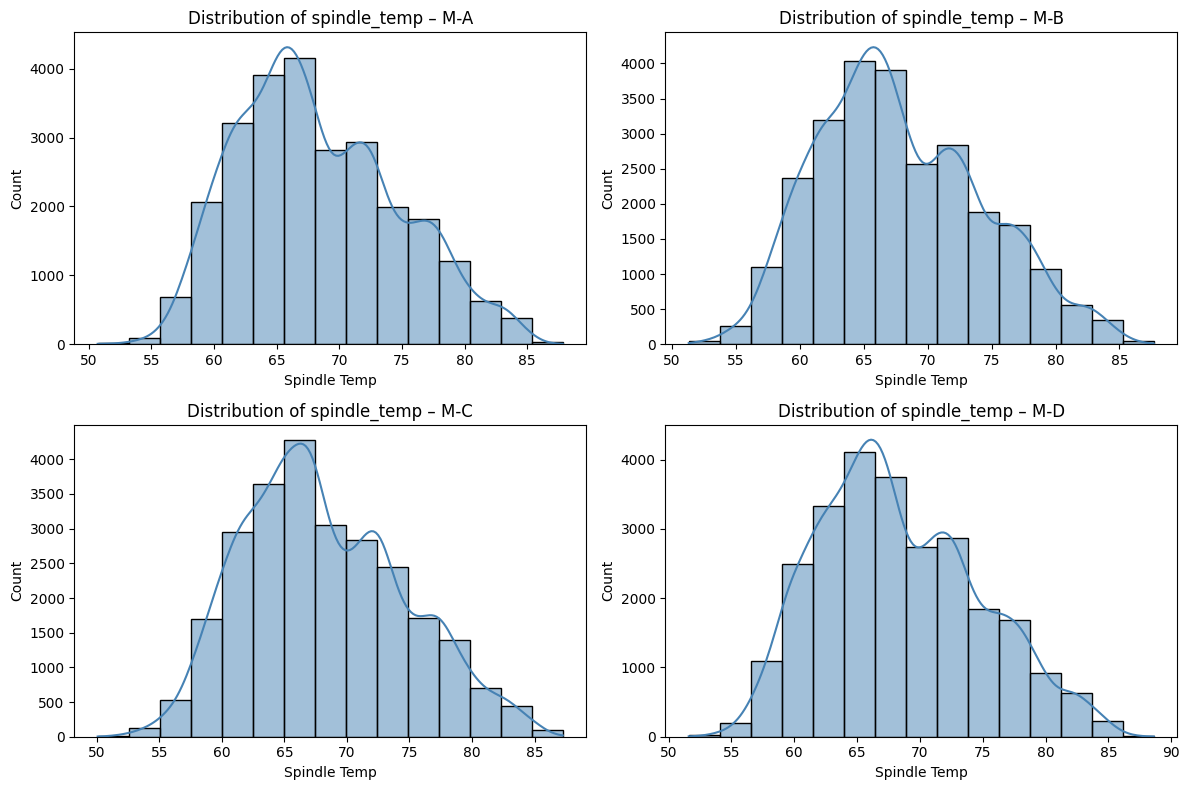

In [ ]:
machines = ['M-A', 'M-B', 'M-C', 'M-D']

plt.figure(figsize=(12, 8))

for i, m in enumerate(machines, 1):
    plt.subplot(2, 2, i)
    sns.histplot(
        data=df.loc[df['machine_id'] == m, 'spindle_temp'],
        kde=True,
        bins=15,
        color='steelblue'
    )
    plt.title(f"Distribution of spindle_temp - {m}")
    plt.xlabel("Spindle Temp")
    plt.tight_layout()

plt.show()

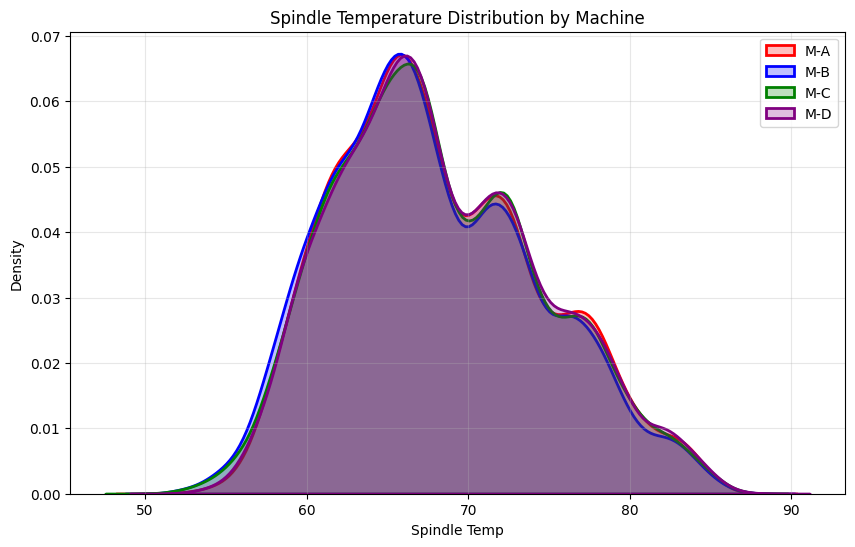

In [37]:
colors = ['red', 'blue', 'green', 'purple']

plt.figure(figsize=(10, 6))

for m, c in zip(machines, colors):
    sns.kdeplot(
        data=df.loc[df['machine_id'] == m, 'spindle_temp'],
        label=m,
        fill=True,
        alpha=0.25,     # transparency so curves can overlap
        linewidth=2,
        color=c
    )

plt.title("Spindle Temperature Distribution by Machine")
plt.xlabel("Spindle Temp")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Distributions are very similiar between machines as such we can consider that they follow the same distribuition and there is no reason to distinguish them.

In [57]:
def calculate_rate(data, min, max, incr, col):
    res={}
    for i in range(min, max, incr):
        res[i]=round(len(data.loc[data[col]>=i])/len(data), 2)
    
    return pd.Series(data=res)

In [ ]:
overheat_rates=calculate_rate(data=df, min=50, max=85, incr=2, col='spindle_temp')
overheat_rates.tail(5)

76    0.14
78    0.08
80    0.04
82    0.02
84    0.01
dtype: float64

In [ ]:
threshold_temp= 78

In [78]:
threshold_temp2= df['spindle_temp'].mean() + 2 * df['spindle_temp'].std()
print(round(threshold_temp2,2))

81.0


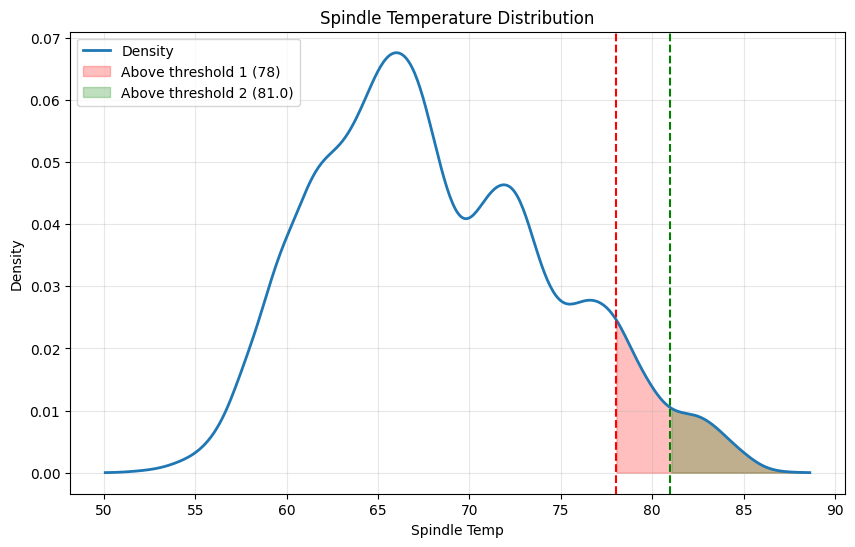

In [92]:
temps = df['spindle_temp']

# Compute KDE manually so we can shade
kde = gaussian_kde(temps)
x = np.linspace(temps.min(), temps.max(), 500)
y = kde(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y, linewidth=2, label="Density")

# --- Shade for threshold 1 ---
x1 = x[x >= threshold_temp]
y1 = y[x >= threshold_temp]
plt.fill_between(x1, y1, alpha=0.25, color='red', label=f"Above threshold 1 ({threshold_temp})")

# --- Shade for threshold 2 ---
x2 = x[x >= threshold_temp2]
y2 = y[x >= threshold_temp2]
plt.fill_between(x2, y2, alpha=0.25, color='green', label=f"Above threshold 2 ({round(threshold_temp2,2)})")

plt.axvline(threshold_temp, color='red', linestyle='--')
plt.axvline(threshold_temp2, color='green', linestyle='--')

plt.title("Spindle Temperature Distribution")
plt.xlabel("Spindle Temp")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The threshold 1 is the one chosen by via the percentage of overheating instances that would be on the dataset (8%), threshold 2 is calculated as the follwing:

$$
\text{threshold 2} = \mu + 2\sigma
$$
**Where:**

- $\mu$ : Mean spindle temperature  
- $\sigma$ : Standard deviation of spindle temperature


The second threshold leads to less than half of instance of threshold 1 however it is more statisctly precise, as such that is the one used going forward in this project

In [94]:
df['spindle_overheat']= df['spindle_temp']>=threshold_temp2

In [95]:
df['spindle_overheat'].value_counts()

spindle_overheat
False    100216
True       3464
Name: count, dtype: int64